
# Geophysical Signal Processing Foundations

## GeoWaveAI

This notebook introduces the basic concepts of geophysical signals and digital signal processing.

We will generate synthetic signals, visualize them, add noise, calculate signal-to-noise ratio, and explore their frequency components using FFT and spectrogram analysis.

### Learning Objectives

By completing this notebook, we will learn to:

1. Understand how a digital signal is represented.
2. Understand sampling rate, amplitude, and frequency.
3. Generate and visualize synthetic signals.
4. Understand the effect of noise.
5. Calculate signal-to-noise ratio (SNR).
6. Explore frequency components using FFT.
7. Understand the basic idea of a spectrogram.

**Note:** All signals in this notebook are synthetic educational examples. They are not real seismic or DAS recordings.


In [1]:
# Import scientific computing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.fft import rfft, rfftfreq

print("Libraries imported successfully!")

Libraries imported successfully!



## 1. Understanding a Geophysical Signal

A geophysical signal is a measurement related to the Earth that changes over time or space.

Examples include:

- **Seismic signals:** Measurements of ground vibrations.
- **Microseismic signals:** Small seismic events that may be related to underground activity, such as rock fractures.
- **DAS signals:** Measurements collected through optical fiber sensing systems.

A digital signal is represented as a sequence of numerical measurements called samples.

For example:

[0.12, 0.18, 0.25, 0.19, -0.05, -0.14]

Each number represents a measurement at a particular sampling time.

In this notebook, we will use synthetic mathematical signals to understand these concepts before working with real geophysical recordings.


In [2]:

# Define the sampling rate and signal duration

sampling_rate = 1000
duration = 2

number_of_samples = sampling_rate * duration

time = np.arange(number_of_samples) / sampling_rate

print("Sampling rate:", sampling_rate, "samples per second")
print("Duration:", duration, "seconds")
print("Number of samples:", number_of_samples)
print("First five time values:", time[:5])


Sampling rate: 1000 samples per second
Duration: 2 seconds
Number of samples: 2000
First five time values: [0.    0.001 0.002 0.003 0.004]


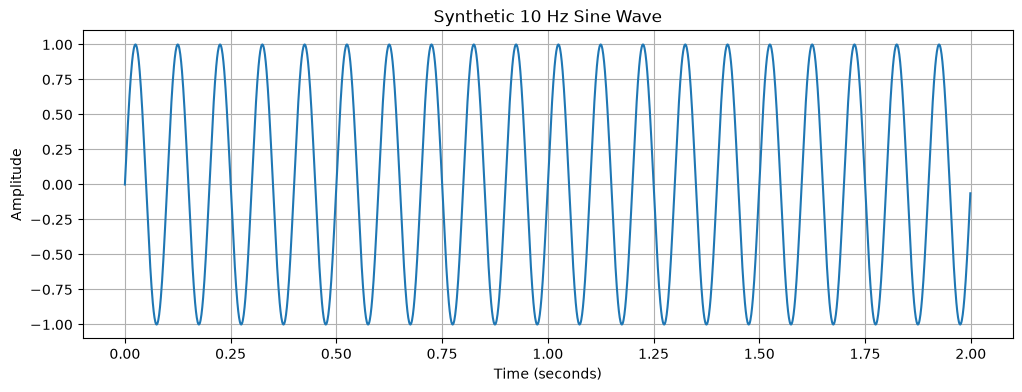

In [3]:

# Generate a synthetic 10 Hz sine wave

frequency = 10
amplitude = 1

sine_signal = amplitude * np.sin(2 * np.pi * frequency * time)

plt.figure(figsize=(12, 4))
plt.plot(time, sine_signal)

plt.title("Synthetic 10 Hz Sine Wave")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()



## 2. Understanding Frequency

Frequency describes how many complete cycles occur in one second.

It is measured in Hertz (Hz).

- A 5 Hz signal completes 5 cycles per second.
- A 10 Hz signal completes 10 cycles per second.
- A 20 Hz signal completes 20 cycles per second.

If two signals have the same amplitude, the higher-frequency signal completes more cycles in the same amount of time.

Frequency is important in geophysical signal processing because different physical events and noise sources may appear at different frequency ranges.


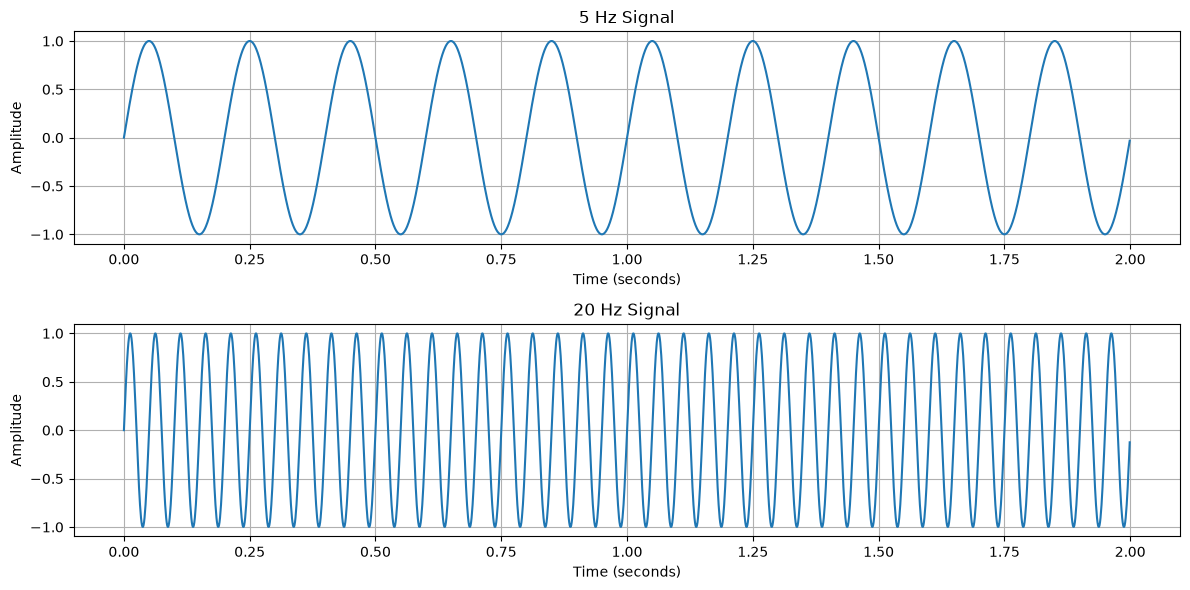

In [4]:

# Compare 5 Hz and 20 Hz signals

frequency_1 = 5
frequency_2 = 20

signal_5hz = np.sin(2 * np.pi * frequency_1 * time)
signal_20hz = np.sin(2 * np.pi * frequency_2 * time)

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(time, signal_5hz)
plt.title("5 Hz Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, signal_20hz)
plt.title("20 Hz Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()



## 3. Combining Multiple Frequencies

A real-world signal may contain several frequency components at the same time.

For example, a measured signal may contain:

- A low-frequency component.
- A high-frequency component.
- Other variations from the surrounding environment.

We can create a simple synthetic signal by adding two sine waves together.

This helps us understand how multiple frequency components can form one combined signal.


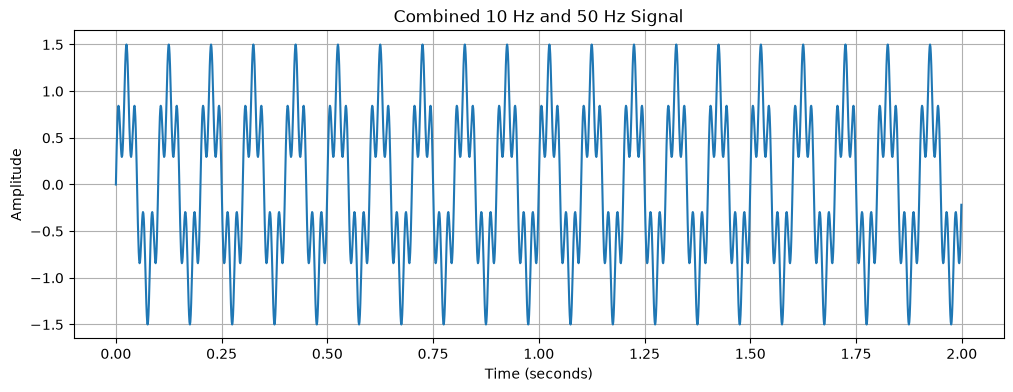

In [5]:

# Combine 10 Hz and 50 Hz signals

low_frequency = 10
high_frequency = 50

signal_10hz = np.sin(2 * np.pi * low_frequency * time)
signal_50hz = 0.5 * np.sin(2 * np.pi * high_frequency * time)

combined_signal = signal_10hz + signal_50hz

plt.figure(figsize=(12, 4))
plt.plot(time, combined_signal)

plt.title("Combined 10 Hz and 50 Hz Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()



## 4. Understanding Noise and Signal-to-Noise Ratio

Noise refers to unwanted variations that affect a measured signal.

In geophysical recordings, noise can come from environmental vibrations, equipment, electrical interference, and other sources.

A signal affected by noise may become more difficult to analyze.

The Signal-to-Noise Ratio (SNR) compares the power of the useful signal with the power of the noise.

A higher SNR generally means the useful signal is stronger compared with the noise.

SNR is commonly expressed in decibels (dB).


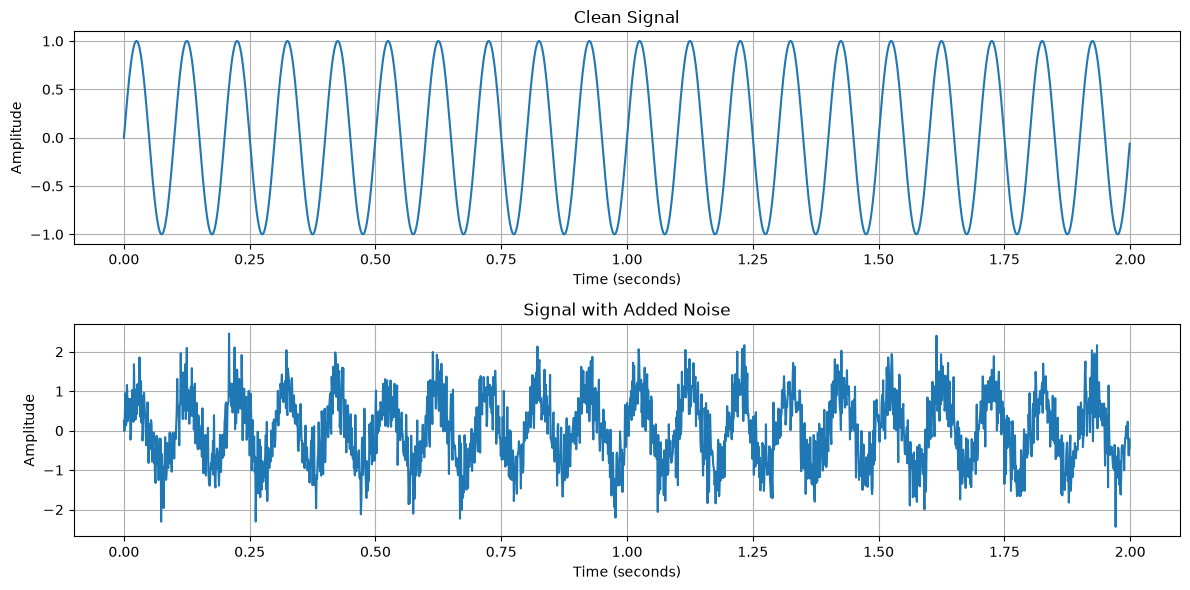

In [6]:

# Add random noise to the synthetic signal

np.random.seed(42)

noise = np.random.normal(0, 0.5, number_of_samples)

clean_signal = sine_signal
noisy_signal = clean_signal + noise

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(time, clean_signal)
plt.title("Clean Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, noisy_signal)
plt.title("Signal with Added Noise")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()


In [7]:

# Calculate Signal-to-Noise Ratio

signal_power = np.mean(clean_signal ** 2)
noise_power = np.mean(noise ** 2)

snr = 10 * np.log10(signal_power / noise_power)

print("Signal Power:", signal_power)
print("Noise Power:", noise_power)
print("Signal-to-Noise Ratio:", snr, "dB")


Signal Power: 0.5
Noise Power: 0.2446521012546182
Signal-to-Noise Ratio: 3.1042105417929386 dB



## 5. Time Domain and Frequency Domain

A signal can be studied in two important ways.

**Time Domain**

The time domain shows how the signal amplitude changes over time.

It helps us observe the shape and behavior of a signal.

**Frequency Domain**

The frequency domain shows which frequencies are present in a signal.

It helps us identify the frequency components that may be difficult to recognize by looking only at the original waveform.

The Fast Fourier Transform (FFT) is a mathematical method used to convert a signal from the time domain into its frequency representation.


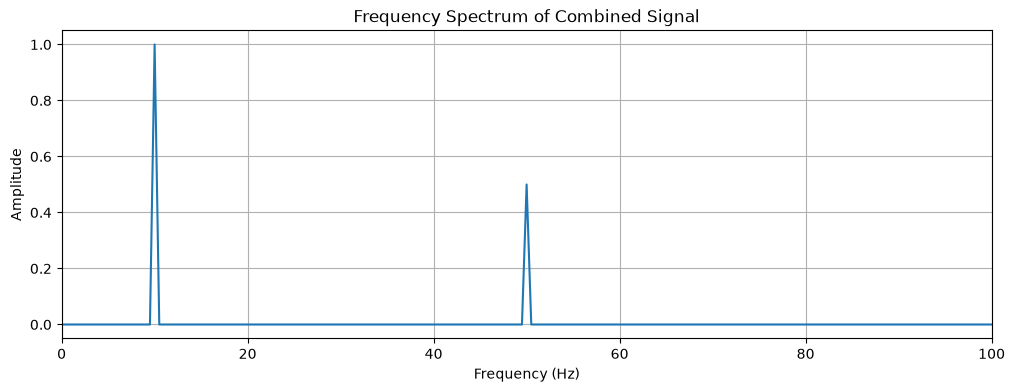

Detected frequency peaks: [10. 50.]


In [8]:

# Perform Fast Fourier Transform (FFT)

fft_values = rfft(combined_signal)
frequencies = rfftfreq(number_of_samples, d=1 / sampling_rate)

amplitude_spectrum = (2 / number_of_samples) * np.abs(fft_values)
amplitude_spectrum[0] = amplitude_spectrum[0] / 2

plt.figure(figsize=(12, 4))
plt.plot(frequencies, amplitude_spectrum)

plt.title("Frequency Spectrum of Combined Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 100)
plt.grid(True)

plt.show()

# Identify the main frequency peaks

peaks, properties = signal.find_peaks(amplitude_spectrum, height=0.1)

print("Detected frequency peaks:", frequencies[peaks])



## 6. Nyquist Frequency and Frequency Resolution

The sampling rate determines how frequently a continuous signal is measured.

The Nyquist frequency is half of the sampling rate.

For example, if the sampling rate is 1000 Hz:

Nyquist frequency = 1000 / 2 = 500 Hz.

A signal must be sampled at more than twice its highest frequency to avoid aliasing under the ideal sampling conditions.

Frequency resolution describes the spacing between frequency points in an FFT.

It can be calculated using:

Frequency Resolution = Sampling Rate / Number of Samples

For our example:

1000 / 2000 = 0.5 Hz.

This means neighboring FFT frequency points are separated by 0.5 Hz.


In [9]:

# Calculate Nyquist frequency and frequency resolution

nyquist_frequency = sampling_rate / 2
frequency_resolution = sampling_rate / number_of_samples

print("Sampling Rate:", sampling_rate, "Hz")
print("Nyquist Frequency:", nyquist_frequency, "Hz")
print("Frequency Resolution:", frequency_resolution, "Hz")


Sampling Rate: 1000 Hz
Nyquist Frequency: 500.0 Hz
Frequency Resolution: 0.5 Hz



## 7. Understanding a Spectrogram

A spectrogram shows how the frequency content of a signal changes over time.

It is commonly calculated using the Short-Time Fourier Transform (STFT).

Unlike a single FFT result, which summarizes frequency content over a selected signal segment, a spectrogram allows us to observe changes in frequency across different time intervals.

In a spectrogram:

- The horizontal axis represents time.
- The vertical axis represents frequency.
- The color intensity represents the signal's power at different times and frequencies.

Spectrogram analysis is useful for studying signals whose frequency content changes over time.


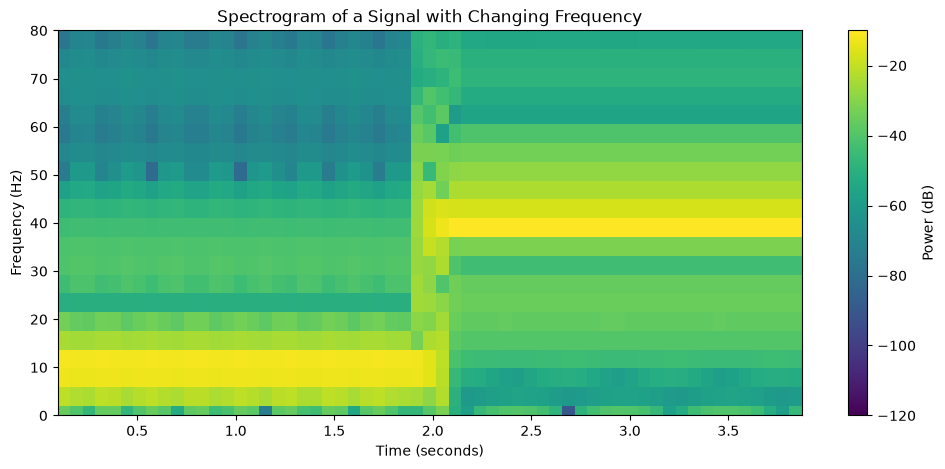

In [10]:

# Create a synthetic signal with changing frequency

spectrogram_duration = 4

spectrogram_time = np.arange(
    sampling_rate * spectrogram_duration
) / sampling_rate

changing_signal = np.zeros(len(spectrogram_time))

# First two seconds: 10 Hz signal
first_half = spectrogram_time < 2

changing_signal[first_half] = np.sin(
    2 * np.pi * 10 * spectrogram_time[first_half]
)

# Last two seconds: 40 Hz signal
second_half = spectrogram_time >= 2

changing_signal[second_half] = np.sin(
    2 * np.pi * 40 * spectrogram_time[second_half]
)

# Calculate the spectrogram

frequencies_spec, times_spec, power_spec = signal.spectrogram(
    changing_signal,
    fs=sampling_rate,
    nperseg=256,
    noverlap=192
)

# Convert power to decibels

power_spec_db = 10 * np.log10(power_spec + 1e-12)

# Visualize the spectrogram

plt.figure(figsize=(12, 5))

plt.pcolormesh(
    times_spec,
    frequencies_spec,
    power_spec_db,
    shading="auto"
)

plt.title("Spectrogram of a Signal with Changing Frequency")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(0, 80)

plt.colorbar(label="Power (dB)")
plt.show()



## 8. Summary and Learning Outcomes

In this notebook, we explored the basic concepts of geophysical signal processing using synthetic signals.

We learned about:

1. Digital signals and their samples.
2. Sampling rate and time representation.
3. Amplitude and frequency.
4. Combining multiple frequency components.
5. Noise and Signal-to-Noise Ratio.
6. Time-domain and frequency-domain analysis.
7. Fast Fourier Transform (FFT).
8. Nyquist frequency and frequency resolution.
9. Spectrogram analysis and changing frequency content.

These concepts provide the foundation for future work in GeoWaveAI.

**Important:** All results in this notebook are based on synthetic educational signals. We have not yet analyzed real seismic or DAS recordings.

In the next stage, we will build on these foundations and begin exploring geophysical signal preprocessing techniques.
